# CIFAR-10 image classification with a CNN in Apple MLX

A convolutional neural network built with **Apple MLX**, which trains on the GPU of Apple silicon Macs. It classifies CIFAR-10 images into 10 classes.

Four designs are compared on a validation set:
1. the baseline CNN;
2. the baseline with dropout;
3. a deeper network with batch normalisation;
4. the deeper network with data augmentation.

The best one is then trained for up to 40 epochs and scored once on the test set (accuracy, precision and recall).

CIFAR-10 (about 170 MB) is downloaded on the first run. Figures are written to `figures/` and the scores to `results.json`.

In [1]:
import json, pickle, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import mlx.core as mx
import mlx.nn as nn
import mlx.optimizers as optim
from mlx.utils import tree_flatten, tree_map
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
SEED = 42
print("MLX", mx.__version__, "on", mx.default_device())

MLX 0.32.4 on Device(gpu, 0)


## 1. Data

CIFAR-10: 60,000 colour images of 32 × 32 pixels in 10 balanced classes. It is read from the standard Python version of the dataset, which is downloaded once (about 170 MB) if no copy is found. The 50,000 training images are split into **45,000 for training and 5,000 for validation**. The 10,000 test images are used **only at the end**. (The course notebook used the test set as validation data during training, which lets test results guide the choices.) Pixels are divided by 255.

In [2]:
DATA = Path.home() / ".keras/datasets/cifar-10-batches-py-target/cifar-10-batches-py"   # copy already downloaded by Keras
if not DATA.exists():   # otherwise download the Python version of CIFAR-10 (about 170 MB) into ./data
    import tarfile, urllib.request
    Path("data").mkdir(exist_ok=True)
    tgz = Path("data/cifar-10-python.tar.gz")
    if not tgz.exists():
        urllib.request.urlretrieve("https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz", tgz)
    with tarfile.open(tgz) as t:
        t.extractall("data", filter="data")
    DATA = Path("data/cifar-10-batches-py")
def load(name):
    with open(DATA / name, "rb") as f:
        d = pickle.load(f, encoding="bytes")
    x = d[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1).astype("float32") / 255.0   # NHWC
    return x, np.array(d[b"labels"])
parts = [load(f"data_batch_{i}") for i in range(1, 6)]
x_full = np.concatenate([p[0] for p in parts]); y_full = np.concatenate([p[1] for p in parts])
x_test, y_test = load("test_batch")
rng = np.random.default_rng(SEED)
idx = rng.permutation(len(x_full))
x_val, y_val = x_full[idx[:5000]], y_full[idx[:5000]]
x_train, y_train = x_full[idx[5000:]], y_full[idx[5000:]]
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
print("train", x_train.shape, "val", x_val.shape, "test", x_test.shape, "| test per class", np.bincount(y_test))

train (45000, 32, 32, 3) val (5000, 32, 32, 3) test (10000, 32, 32, 3) | test per class [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


## 2. Models

Four models, each adding one change, so the effect of each change can be seen:

1. **Baseline:** the course CNN (3 conv layers, 2 max-pool layers, Dense 64).
2. **+ Dropout:** the same with dropout 0.5 before the output layer.
3. **Deeper + BatchNorm:** three blocks of two 3 × 3 conv layers (32, 64, 128 filters), each followed by batch normalisation and ReLU, then max pooling and rising dropout (0.2, 0.3, 0.4), then Dense 128 with dropout 0.5.
4. **Deeper + BatchNorm + augmentation:** model 3 trained on randomly flipped and shifted copies of the training images.

In [3]:
class Baseline(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.c1, self.c2, self.c3 = nn.Conv2d(3, 32, 3), nn.Conv2d(32, 64, 3), nn.Conv2d(64, 64, 3)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1, self.fc2 = nn.Linear(4 * 4 * 64, 64), nn.Linear(64, 10)
        self.drop = nn.Dropout(dropout) if dropout else None
    def __call__(self, x):
        x = self.pool(nn.relu(self.c1(x)))
        x = self.pool(nn.relu(self.c2(x)))
        x = nn.relu(self.c3(x))
        x = nn.relu(self.fc1(x.reshape(x.shape[0], -1)))
        if self.drop is not None: x = self.drop(x)
        return self.fc2(x)

class Block(nn.Module):
    def __init__(self, cin, cout, drop):
        super().__init__()
        self.conv1, self.bn1 = nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm(cout)
        self.conv2, self.bn2 = nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm(cout)
        self.pool, self.drop = nn.MaxPool2d(2, 2), nn.Dropout(drop)
    def __call__(self, x):
        x = nn.relu(self.bn1(self.conv1(x)))
        x = nn.relu(self.bn2(self.conv2(x)))
        return self.drop(self.pool(x))

class Deeper(nn.Module):
    def __init__(self):
        super().__init__()
        self.b1, self.b2, self.b3 = Block(3, 32, 0.2), Block(32, 64, 0.3), Block(64, 128, 0.4)
        self.fc1, self.drop, self.fc2 = nn.Linear(4 * 4 * 128, 128), nn.Dropout(0.5), nn.Linear(128, 10)
    def __call__(self, x):
        x = self.b3(self.b2(self.b1(x)))
        x = self.drop(nn.relu(self.fc1(x.reshape(x.shape[0], -1))))
        return self.fc2(x)

def n_params(m):
    return sum(v.size for _, v in tree_flatten(m.trainable_parameters()))

def augment(xb, rng):
    # random horizontal flip and a random shift of up to 3 pixels (pad 3, then crop 32 x 32)
    flip = rng.random(len(xb)) < 0.5
    xb = xb.copy(); xb[flip] = xb[flip, :, ::-1]
    padded = np.pad(xb, ((0, 0), (3, 3), (3, 3), (0, 0)), mode="reflect")
    out = np.empty_like(xb)
    dy, dx = rng.integers(0, 7, len(xb)), rng.integers(0, 7, len(xb))
    for i in range(len(xb)):
        out[i] = padded[i, dy[i]:dy[i] + 32, dx[i]:dx[i] + 32]
    return out

**Training loop.** Adam with a starting learning rate of 0.001, batches of 64 and cross-entropy loss. The learning rate halves when the validation loss has not improved for 3 epochs. Optional early stopping restores the weights from the best epoch.

In [4]:
def loss_fn(model, x, y):
    return nn.losses.cross_entropy(model(x), y, reduction="mean")

def evaluate(model, x, y, bs=1000):
    model.eval()
    losses, preds = [], []
    for i in range(0, len(x), bs):
        logits = model(mx.array(x[i:i + bs]))
        losses.append(nn.losses.cross_entropy(logits, mx.array(y[i:i + bs]), reduction="sum").item())
        preds.append(np.array(mx.argmax(logits, axis=1)))
    p = np.concatenate(preds)
    return sum(losses) / len(x), float((p == y).mean()), p

def train(model, epochs, aug=False, lr=1e-3, patience=None, bs=64, name=""):
    mx.random.seed(SEED); rng = np.random.default_rng(SEED)
    opt = optim.Adam(learning_rate=lr)
    step_fn = nn.value_and_grad(model, loss_fn)
    hist = {k: [] for k in ["loss", "accuracy", "val_loss", "val_accuracy", "lr"]}
    best_loss, best_w, wait, plateau = np.inf, None, 0, 0
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        order = rng.permutation(len(x_train)); tl, tc = 0.0, 0
        for i in range(0, len(order), bs):
            b = order[i:i + bs]
            xb = augment(x_train[b], rng) if aug else x_train[b]
            xb, yb = mx.array(xb), mx.array(y_train[b])
            loss, grads = step_fn(model, xb, yb)
            opt.update(model, grads)
            mx.eval(model.parameters(), opt.state, loss)
            tl += loss.item() * len(b)
        tr_loss, tr_acc, _ = evaluate(model, x_train[:10000], y_train[:10000])
        vl, va, _ = evaluate(model, x_val, y_val)
        for k, v in zip(hist, [tl / len(order), tr_acc, vl, va, float(opt.learning_rate.item() if hasattr(opt.learning_rate, 'item') else opt.learning_rate)]): hist[k].append(v)
        print(f"{name} epoch {ep+1:2d}  loss {tl/len(order):.3f}  train acc {tr_acc:.3f}  val loss {vl:.3f}  val acc {va:.3f}  lr {hist['lr'][-1]:.5f}  {time.time()-t0:.0f}s", flush=True)
        if vl < best_loss - 1e-4:
            best_loss, wait, plateau = vl, 0, 0
            best_w = tree_map(lambda a: mx.array(a), model.parameters())
        else:
            wait += 1; plateau += 1
            if plateau >= 3:
                opt.learning_rate = max(float(hist["lr"][-1]) * 0.5, 1e-5); plateau = 0
            if patience and wait >= patience:
                print("early stopping"); break
    if patience and best_w is not None:
        model.update(best_w); mx.eval(model.parameters())
    return hist, time.time() - t0

## 3. Hyperparameter tuning

Each setting is trained for 15 epochs and judged on the **validation** set only.

In [5]:
settings = {"Baseline (course CNN)": (lambda: Baseline(), False),
            "Baseline + dropout": (lambda: Baseline(0.5), False),
            "Deeper + BatchNorm": (lambda: Deeper(), False),
            "Deeper + BatchNorm + augmentation": (lambda: Deeper(), True)}
tuning, histories, tuned_models = {}, {}, {}
for name, (build, aug) in settings.items():
    mx.random.seed(SEED)
    m = build(); mx.eval(m.parameters())
    h, secs = train(m, 15, aug=aug, name=name[:12])
    tuning[name] = {"params": int(n_params(m)), "best_val_acc": max(h["val_accuracy"]),
                    "final_train_acc": h["accuracy"][-1], "final_val_acc": h["val_accuracy"][-1],
                    "best_val_loss_epoch": int(np.argmin(h["val_loss"])) + 1, "min_val_loss": min(h["val_loss"]),
                    "final_val_loss": h["val_loss"][-1], "seconds": round(secs)}
    histories[name], tuned_models[name] = h, m
    print("==", name, {k: (round(v, 4) if isinstance(v, float) else v) for k, v in tuning[name].items()})

Baseline (co epoch  1  loss 1.675  train acc 0.469  val loss 1.476  val acc 0.459  lr 0.00100  3s


Baseline (co epoch  2  loss 1.375  train acc 0.475  val loss 1.492  val acc 0.480  lr 0.00100  6s


Baseline (co epoch  3  loss 1.282  train acc 0.562  val loss 1.250  val acc 0.546  lr 0.00100  8s


Baseline (co epoch  4  loss 1.211  train acc 0.581  val loss 1.200  val acc 0.567  lr 0.00100  11s


Baseline (co epoch  5  loss 1.160  train acc 0.605  val loss 1.147  val acc 0.585  lr 0.00100  14s


Baseline (co epoch  6  loss 1.116  train acc 0.619  val loss 1.125  val acc 0.599  lr 0.00100  16s


... (54 outputs left out)

Deeper + Bat epoch 13  loss 1.286  train acc 0.656  val loss 1.014  val acc 0.636  lr 0.00100  280s


Deeper + Bat epoch 14  loss 1.269  train acc 0.732  val loss 0.861  val acc 0.714  lr 0.00100  302s


Deeper + Bat epoch 15  loss 1.232  train acc 0.746  val loss 0.804  val acc 0.732  lr 0.00100  323s


== Deeper + BatchNorm + augmentation {'params': 551018, 'best_val_acc': 0.732, 'final_train_acc': 0.7462, 'final_val_acc': 0.732, 'best_val_loss_epoch': 15, 'min_val_loss': 0.8043, 'final_val_loss': 0.8043, 'seconds': 323}


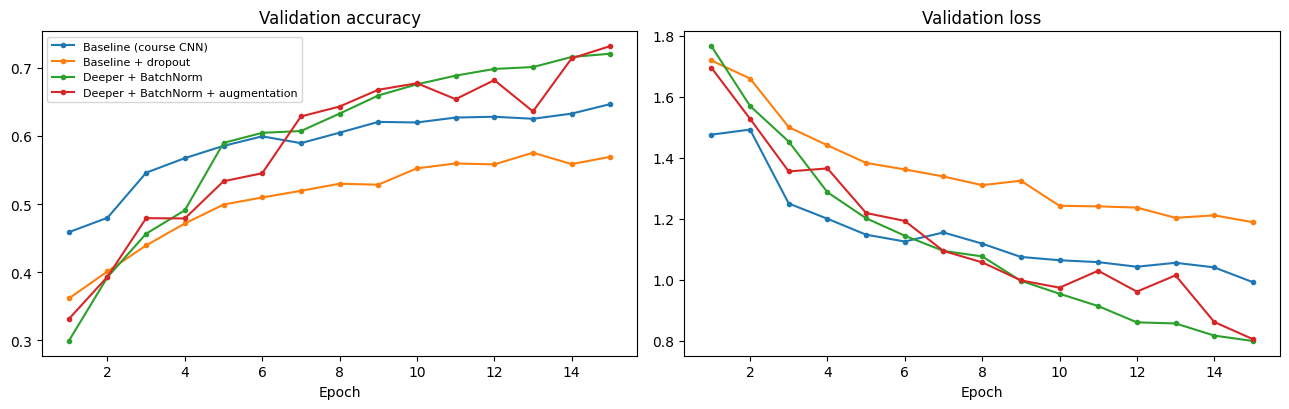

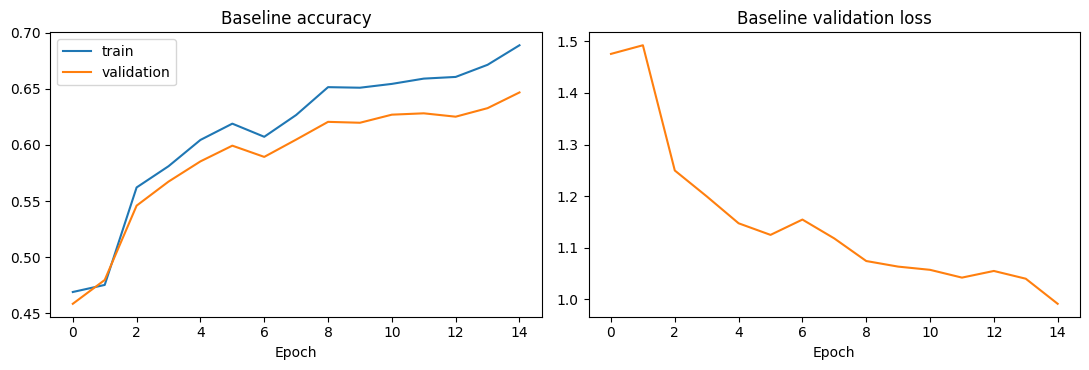

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for name, h in histories.items():
    e = range(1, len(h["val_accuracy"]) + 1)
    axes[0].plot(e, h["val_accuracy"], marker="o", ms=3, label=name)
    axes[1].plot(e, h["val_loss"], marker="o", ms=3, label=name)
axes[0].set_title("Validation accuracy"); axes[1].set_title("Validation loss")
for ax in axes: ax.set_xlabel("Epoch")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "tuning_curves.png", dpi=150); plt.show()
h = histories["Baseline (course CNN)"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(h["accuracy"], label="train"); axes[0].plot(h["val_accuracy"], label="validation"); axes[0].set_title("Baseline accuracy")
axes[1].plot(h["val_loss"], color="tab:orange"); axes[1].set_title("Baseline validation loss")
for ax in axes: ax.set_xlabel("Epoch")
axes[0].legend()
plt.tight_layout(); plt.savefig(FIG / "baseline_overfitting.png", dpi=150); plt.show()

## 4. Final model

The best setting (deeper network with batch normalisation, dropout and augmentation) is trained for up to 40 epochs with learning-rate halving and **early stopping** (patience 6, best weights restored).

parameters: 551018


final epoch  1  loss 1.974  train acc 0.337  val loss 1.695  val acc 0.331  lr 0.00100  23s


final epoch  2  loss 1.780  train acc 0.403  val loss 1.528  val acc 0.393  lr 0.00100  44s


final epoch  3  loss 1.650  train acc 0.492  val loss 1.355  val acc 0.479  lr 0.00100  67s


final epoch  4  loss 1.583  train acc 0.486  val loss 1.365  val acc 0.479  lr 0.00100  89s


final epoch  5  loss 1.535  train acc 0.541  val loss 1.218  val acc 0.533  lr 0.00100  110s


... (32 outputs left out)

final epoch 38  loss 0.770  train acc 0.857  val loss 0.517  val acc 0.827  lr 0.00050  845s


final epoch 39  loss 0.762  train acc 0.853  val loss 0.533  val acc 0.820  lr 0.00050  864s


final epoch 40  loss 0.751  train acc 0.863  val loss 0.517  val acc 0.829  lr 0.00050  882s


epochs run 40   time 14.7 min   best val acc 0.8286


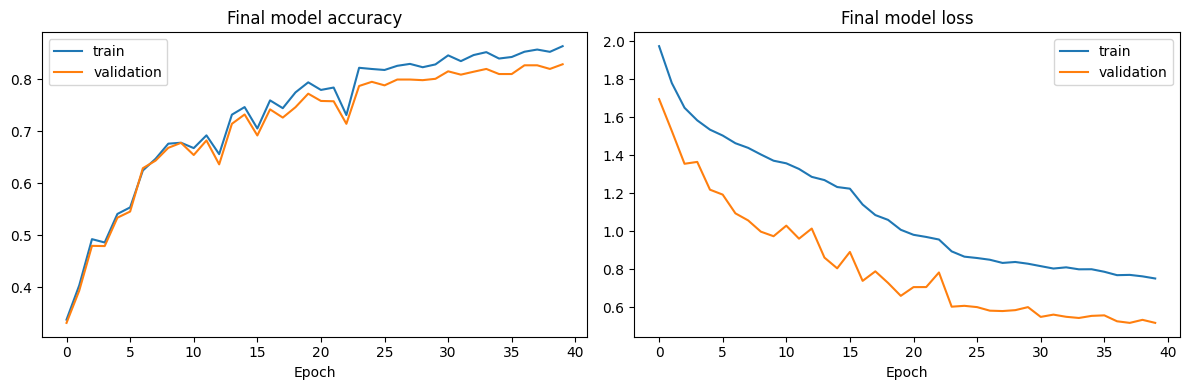

In [7]:
mx.random.seed(SEED)
final = Deeper(); mx.eval(final.parameters())
print("parameters:", n_params(final))
fh, final_secs = train(final, 40, aug=True, patience=6, name="final")
print(f"epochs run {len(fh['loss'])}   time {final_secs/60:.1f} min   best val acc {max(fh['val_accuracy']):.4f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(fh["accuracy"], label="train"); axes[0].plot(fh["val_accuracy"], label="validation"); axes[0].set_title("Final model accuracy")
axes[1].plot(fh["loss"], label="train"); axes[1].plot(fh["val_loss"], label="validation"); axes[1].set_title("Final model loss")
for ax in axes: ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "final_curves.png", dpi=150); plt.show()

## 5. Evaluation on the test set

The 10,000 test images are used here for the first time. Precision and recall are given per class and as macro averages (each class counts equally; the classes are balanced). The baseline from the tuning step is scored the same way for comparison.

In [8]:
test_loss, test_acc, y_pred = evaluate(final, x_test, y_test)
prec, rec, f1 = (precision_score(y_test, y_pred, average="macro"), recall_score(y_test, y_pred, average="macro"), f1_score(y_test, y_pred, average="macro"))
report = classification_report(y_test, y_pred, target_names=class_names, digits=3)
print(f"FINAL test accuracy {test_acc:.4f}  loss {test_loss:.4f}  macro precision {prec:.4f}  macro recall {rec:.4f}  macro F1 {f1:.4f}")
print(report)
test_scores = {}
for name, m in tuned_models.items():
    _, a, p = evaluate(m, x_test, y_test)
    test_scores[name] = {"accuracy": a, "precision": precision_score(y_test, p, average="macro"),
                         "recall": recall_score(y_test, p, average="macro"), "f1": f1_score(y_test, p, average="macro")}
    print(f"{name:36s} test acc {a:.4f}  precision {test_scores[name]['precision']:.4f}  recall {test_scores[name]['recall']:.4f}")

FINAL test accuracy 0.8258  loss 0.5408  macro precision 0.8311  macro recall 0.8258  macro F1 0.8270
              precision    recall  f1-score   support

    airplane      0.865     0.828     0.846      1000
  automobile      0.938     0.931     0.934      1000
        bird      0.798     0.729     0.762      1000
         cat      0.583     0.685     0.630      1000
        deer      0.884     0.778     0.828      1000
         dog      0.709     0.711     0.710      1000
        frog      0.841     0.902     0.871      1000
       horse      0.929     0.826     0.875      1000
        ship      0.884     0.937     0.910      1000
       truck      0.879     0.931     0.904      1000

    accuracy                          0.826     10000
   macro avg      0.831     0.826     0.827     10000
weighted avg      0.831     0.826     0.827     10000

Baseline (course CNN)                test acc 0.6575  precision 0.6558  recall 0.6575


Baseline + dropout                   test acc 0.5715  precision 0.5822  recall 0.5715


Deeper + BatchNorm                   test acc 0.7286  precision 0.7363  recall 0.7286


Deeper + BatchNorm + augmentation    test acc 0.7346  precision 0.7401  recall 0.7346


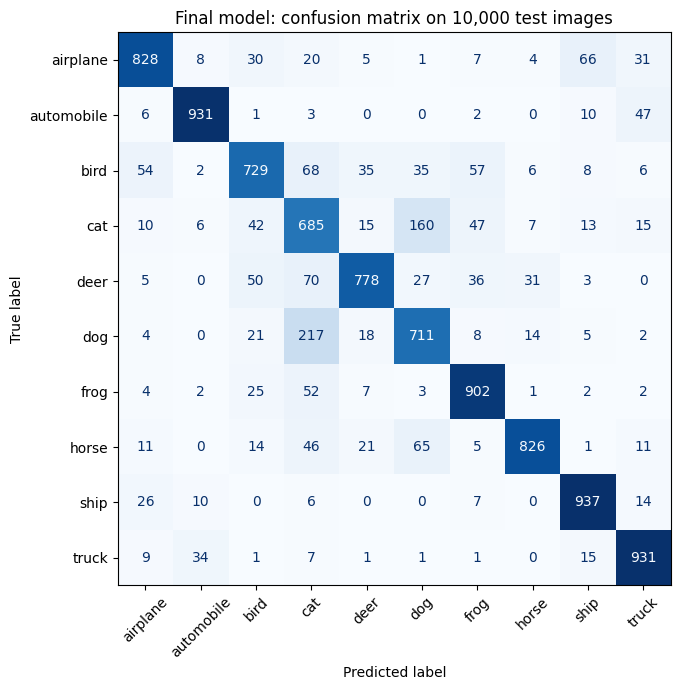

most common mistakes: [(217, 'dog', 'cat'), (160, 'cat', 'dog'), (70, 'deer', 'cat'), (68, 'bird', 'cat'), (66, 'airplane', 'ship')]


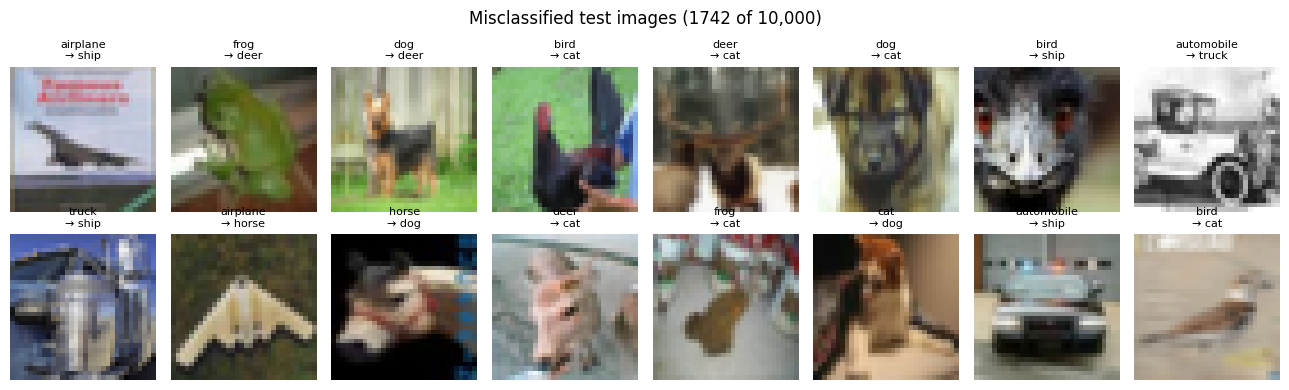

In [9]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
ax.set_title("Final model: confusion matrix on 10,000 test images")
plt.tight_layout(); plt.savefig(FIG / "confusion_matrix.png", dpi=150); plt.show()
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted([(int(off[i, j]), class_names[i], class_names[j]) for i in range(10) for j in range(10) if off[i, j]], reverse=True)[:5]
print("most common mistakes:", pairs)
wrong = np.where(y_pred != y_test)[0]
fig, axes = plt.subplots(2, 8, figsize=(13, 4))
for ax, i in zip(axes.ravel(), wrong[:16]):
    ax.imshow(x_test[i]); ax.set_title(f"{class_names[y_test[i]]}\n→ {class_names[y_pred[i]]}", fontsize=8); ax.axis("off")
plt.suptitle(f"Misclassified test images ({len(wrong)} of 10,000)")
plt.tight_layout(); plt.savefig(FIG / "mistakes.png", dpi=150); plt.show()

In [10]:
per_class = {class_names[i]: {"precision": float(cm[i, i] / cm[:, i].sum()), "recall": float(cm[i, i] / cm[i].sum())} for i in range(10)}
Path("results.json").write_text(json.dumps({
    "tuning": tuning, "test_scores": test_scores,
    "final": {"test_acc": test_acc, "test_loss": test_loss, "precision": float(prec), "recall": float(rec), "f1": float(f1),
              "epochs": len(fh["loss"]), "minutes": round(final_secs / 60, 1), "best_val_acc": max(fh["val_accuracy"]),
              "final_train_acc": fh["accuracy"][-1], "params": int(n_params(final))},
    "per_class": per_class, "top_mistakes": pairs, "n_wrong": int(len(wrong)), "report": report,
    "mlx": mx.__version__, "device": str(mx.default_device())}, indent=1))
print("saved results.json")

saved results.json
